# LogiCast — Baseline Model Development

## Objective
Train and evaluate machine-learning models to predict late-delivery risk.

## Target
`Late_delivery_risk`

## Models
1. Dummy Classifier
2. Logistic Regression
3. Random Forest
4. XGBoost

## Evaluation
- ROC-AUC
- PR-AUC
- Precision, Recall and F1-score
- Confusion Matrix

## Methodology
- Preserve the chronological 80/20 train-test split.
- Reuse the preprocessing pipeline from Notebook 02.
- Fit candidate models on training data only.
- Reserve the test set for final evaluation.

**Important:** This notebook does not yet deploy the model or establish production performance.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
)

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
PROJECT_ROOT = Path.cwd().parent

PROCESSED_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "supply_chain_cleaned.csv"
)

MODEL_DIR = (
    PROJECT_ROOT
    / "src"
    / "models"
)

PREPROCESSOR_PATH = (
    MODEL_DIR
    / "preprocessor.joblib"
)

FEATURES_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "feature_columns.txt"
)

assert PROCESSED_PATH.exists(), (
    f"Cleaned dataset not found: {PROCESSED_PATH}"
)

assert PREPROCESSOR_PATH.exists(), (
    f"Preprocessor not found: {PREPROCESSOR_PATH}"
)

assert FEATURES_PATH.exists(), (
    f"Feature list not found: {FEATURES_PATH}"
)

print("Project paths verified.")

Project paths verified.


In [3]:
df = pd.read_csv(PROCESSED_PATH)

preprocessor = joblib.load(PREPROCESSOR_PATH)

feature_cols = FEATURES_PATH.read_text().splitlines()

TARGET = "Late_delivery_risk"
ORDER_DATE = "order date (DateOrders)"

print("Dataset shape:", df.shape)
print("Feature count:", len(feature_cols))
print("Preprocessor loaded:", type(preprocessor).__name__)

display(df.head())

Dataset shape: (180519, 23)
Feature count: 17
Preprocessor loaded: ColumnTransformer


,Type,Days for shipment (scheduled),Late_delivery_risk,Category Name,Customer City,Customer Country,Customer Segment,Customer State,Department Name,Market,...,Order Item Discount,Order Item Discount Rate,Order Item Product Price,Order Item Quantity,Order Region,Order State,Shipping Mode,Order_Month,Order_DayOfWeek,Order_Day
0,DEBIT,4,0,Sporting Goods,Caguas,Puerto Rico,Consumer,PR,Fitness,Pacific Asia,...,13.110000,0.04,327.75,1,Southeast Asia,Java Occidental,Standard Class,1,2,31
1,TRANSFER,4,1,Sporting Goods,Caguas,Puerto Rico,Consumer,PR,Fitness,Pacific Asia,...,16.389999,0.05,327.75,1,South Asia,Rajastán,Standard Class,1,5,13
2,CASH,4,0,Sporting Goods,San Jose,EE. UU.,Consumer,CA,Fitness,Pacific Asia,...,18.030001,0.06,327.75,1,South Asia,Rajastán,Standard Class,1,5,13
3,DEBIT,4,0,Sporting Goods,Los Angeles,EE. UU.,Home Office,CA,Fitness,Pacific Asia,...,22.940001,0.07,327.75,1,Oceania,Queensland,Standard Class,1,5,13
4,PAYMENT,4,0,Sporting Goods,Caguas,Puerto Rico,Corporate,PR,Fitness,Pacific Asia,...,29.500000,0.09,327.75,1,Oceania,Queensland,Standard Class,1,5,13


In [4]:
df[ORDER_DATE] = pd.to_datetime(
    df[ORDER_DATE],
    errors="coerce"
)

df = (
    df
    .dropna(subset=[TARGET, ORDER_DATE])
    .sort_values(ORDER_DATE)
    .reset_index(drop=True)
)

df[TARGET] = df[TARGET].astype(int)

split_index = int(len(df) * 0.80)

train_df = df.iloc[:split_index].copy()
test_df = df.iloc[split_index:].copy()

print("Training rows:", len(train_df))
print("Testing rows:", len(test_df))

print("\nTraining period:")
print(train_df[ORDER_DATE].min(), "to", train_df[ORDER_DATE].max())

print("\nTesting period:")
print(test_df[ORDER_DATE].min(), "to", test_df[ORDER_DATE].max())

Training rows: 144415
Testing rows: 36104

Training period:
2015-01-01 00:00:00 to 2017-04-22 15:17:00

Testing period:
2017-04-22 15:17:00 to 2018-01-31 23:38:00


In [5]:
X_train = train_df[feature_cols].copy()
y_train = train_df[TARGET].copy()

X_test = test_df[feature_cols].copy()
y_test = test_df[TARGET].copy()

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).sort_index())

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).sort_index())

X_train: (144415, 17)
X_test : (36104, 17)

Training target distribution:
Late_delivery_risk
0    0.451276
1    0.548724
Name: proportion, dtype: float64

Testing target distribution:
Late_delivery_risk
0    0.45344
1    0.54656
Name: proportion, dtype: float64


In [6]:
X_train_processed = preprocessor.transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape :", X_test_processed.shape)

Processed training shape: (144415, 1327)
Processed testing shape : (36104, 1327)


In [7]:
dummy_model = DummyClassifier(
    strategy="most_frequent"
)

dummy_model.fit(
    X_train_processed,
    y_train
)

dummy_predictions = dummy_model.predict(
    X_test_processed
)

print(
    classification_report(
        y_test,
        dummy_predictions,
        zero_division=0
    )
)

              precision    recall  f1-score   support

           0       0.00      0.00      0.00     16371
           1       0.55      1.00      0.71     19733

    accuracy                           0.55     36104
   macro avg       0.27      0.50      0.35     36104
weighted avg       0.30      0.55      0.39     36104



In [8]:
def evaluate_model(name, model, X, y):
    predictions = model.predict(X)

    if hasattr(model, "predict_proba"):
        probabilities = model.predict_proba(X)[:, 1]
    else:
        probabilities = model.decision_function(X)

    return {
        "Model": name,
        "Accuracy": accuracy_score(y, predictions),
        "Precision": precision_score(
            y, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y, predictions, zero_division=0
        ),
        "F1": f1_score(
            y, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y, probabilities),
        "PR-AUC": average_precision_score(y, probabilities),
    }

In [9]:
logistic_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

logistic_model.fit(
    X_train_processed,
    y_train
)

logistic_results = evaluate_model(
    "Logistic Regression",
    logistic_model,
    X_test_processed,
    y_test
)

print(logistic_results)

{'Model': 'Logistic Regression', 'Accuracy': 0.688871039220031, 'Precision': 0.8306363777812354, 'Recall': 0.5410733289413673, 'F1': 0.6552919876024181, 'ROC-AUC': 0.7371203486649389, 'PR-AUC': 0.8063520757043678}


In [10]:
random_forest_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=20,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

random_forest_model.fit(
    X_train_processed,
    y_train
)

random_forest_results = evaluate_model(
    "Random Forest",
    random_forest_model,
    X_test_processed,
    y_test
)

print(random_forest_results)

{'Model': 'Random Forest', 'Accuracy': 0.6918070019942388, 'Precision': 0.8297823421213979, 'Recall': 0.5486748086960929, 'F1': 0.6605655715200879, 'ROC-AUC': 0.7437223219764567, 'PR-AUC': 0.8140451526739321}


In [11]:
results = pd.DataFrame([
    evaluate_model(
        "Dummy Classifier",
        dummy_model,
        X_test_processed,
        y_test
    ),
    logistic_results,
    random_forest_results,
])

results = results.sort_values(
    "PR-AUC",
    ascending=False
).reset_index(drop=True)

display(
    results.style.format({
        "Accuracy": "{:.3f}",
        "Precision": "{:.3f}",
        "Recall": "{:.3f}",
        "F1": "{:.3f}",
        "ROC-AUC": "{:.3f}",
        "PR-AUC": "{:.3f}",
    })
)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Random Forest,0.692,0.830,0.549,0.661,0.744,0.814
1,Logistic Regression,0.689,0.831,0.541,0.655,0.737,0.806
2,Dummy Classifier,0.547,0.547,1.000,0.707,0.500,0.547


In [12]:
%pip install xgboost


[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [13]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(
    X_train_processed,
    y_train
)

xgb_results = evaluate_model(
    "XGBoost",
    xgb_model,
    X_test_processed,
    y_test
)

print(xgb_results)

{'Model': 'XGBoost', 'Accuracy': 0.6897296698426767, 'Precision': 0.8285450204113071, 'Recall': 0.5451274514772209, 'F1': 0.6575987284509108, 'ROC-AUC': 0.7428387855768344, 'PR-AUC': 0.8120306747169097}


In [14]:
results = pd.DataFrame([
    evaluate_model(
        "Dummy Classifier",
        dummy_model,
        X_test_processed,
        y_test
    ),
    logistic_results,
    random_forest_results,
    xgb_results
])

results = (
    results
    .sort_values("PR-AUC", ascending=False)
    .reset_index(drop=True)
)

display(
    results.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}",
        "ROC-AUC": "{:.4f}",
        "PR-AUC": "{:.4f}",
    })
)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Random Forest,0.6918,0.8298,0.5487,0.6606,0.7437,0.8140
1,XGBoost,0.6897,0.8285,0.5451,0.6576,0.7428,0.8120
2,Logistic Regression,0.6889,0.8306,0.5411,0.6553,0.7371,0.8064
3,Dummy Classifier,0.5466,0.5466,1.0000,0.7068,0.5000,0.5466


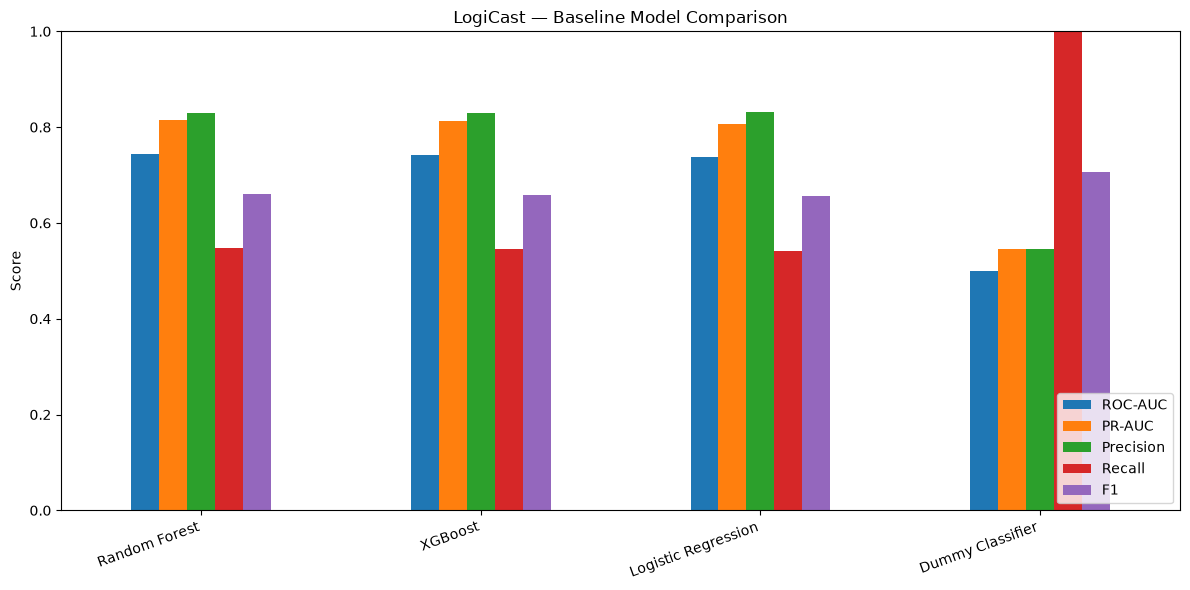

In [15]:
metrics_to_plot = [
    "ROC-AUC",
    "PR-AUC",
    "Precision",
    "Recall",
    "F1"
]

plot_data = results.set_index("Model")[metrics_to_plot]

ax = plot_data.plot(
    kind="bar",
    figsize=(12, 6)
)

ax.set_title("LogiCast — Baseline Model Comparison")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.set_xlabel("")
plt.xticks(rotation=20, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

Top model by PR-AUC: Random Forest

Classification report:
              precision    recall  f1-score   support

           0       0.61      0.86      0.72     16371
           1       0.83      0.55      0.66     19733

    accuracy                           0.69     36104
   macro avg       0.72      0.71      0.69     36104
weighted avg       0.73      0.69      0.69     36104



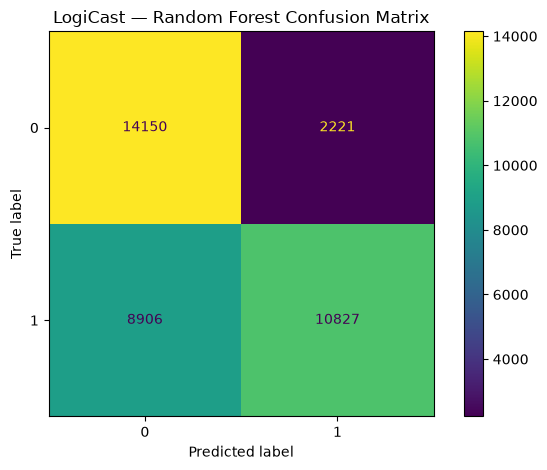

In [16]:
model_lookup = {
    "Dummy Classifier": dummy_model,
    "Logistic Regression": logistic_model,
    "Random Forest": random_forest_model,
    "XGBoost": xgb_model,
}

best_name = results.iloc[0]["Model"]
best_model = model_lookup[best_name]

best_predictions = best_model.predict(
    X_test_processed
)

print("Top model by PR-AUC:", best_name)

print("\nClassification report:")
print(
    classification_report(
        y_test,
        best_predictions,
        zero_division=0
    )
)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    best_predictions,
    values_format="d"
)

plt.title(f"LogiCast — {best_name} Confusion Matrix")
plt.tight_layout()
plt.show()

In [17]:
REPORT_DIR = PROJECT_ROOT / "reports"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

RESULTS_PATH = REPORT_DIR / "baseline_model_comparison.csv"

results.to_csv(
    RESULTS_PATH,
    index=False
)

print("Model comparison saved to:", RESULTS_PATH)

Model comparison saved to: /Users/Kushagra/Desktop/Code/LogiCast/reports/baseline_model_comparison.csv


In [18]:
# Cell 19 — Save the best baseline model

import json

MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

BEST_MODEL_PATH = MODEL_DIR / "best_baseline_model.joblib"
METRICS_PATH = MODEL_DIR / "best_model_metrics.json"

# Save the selected model
joblib.dump(
    best_model,
    BEST_MODEL_PATH
)

# Save its evaluation metrics
best_metrics = results.loc[
    results["Model"] == best_name
].iloc[0].to_dict()

with open(METRICS_PATH, "w") as f:
    json.dump(best_metrics, f, indent=4)

print("Selected model:", best_name)
print("Model saved to:", BEST_MODEL_PATH)
print("Metrics saved to:", METRICS_PATH)

Selected model: Random Forest
Model saved to: /Users/Kushagra/Desktop/Code/LogiCast/src/models/best_baseline_model.joblib
Metrics saved to: /Users/Kushagra/Desktop/Code/LogiCast/src/models/best_model_metrics.json


In [19]:
# Cell 23 — Feature Importance

import pandas as pd
import matplotlib.pyplot as plt

# Get encoded feature names from the fitted preprocessor
feature_names = preprocessor.get_feature_names_out()

# Extract feature importance from Random Forest
importance_values = best_model.feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values
})

# Sort by importance
importance_df = importance_df.sort_values(
    "Importance",
    ascending=False
).reset_index(drop=True)

print("Top 20 encoded features:")
display(importance_df.head(20))

Top 20 encoded features:


,Feature,Importance
0,categorical__Shipping Mode_Standard Class,0.263208
1,numeric__Days for shipment (scheduled),0.252338
2,categorical__Shipping Mode_First Class,0.234097
3,categorical__Shipping Mode_Second Class,0.102273
4,categorical__Shipping Mode_Same Day,0.031237
5,categorical__Type_TRANSFER,0.021635
6,categorical__Type_DEBIT,0.005346
7,categorical__Type_PAYMENT,0.004711
8,numeric__Order Item Discount,0.002974
9,numeric__Order Item Discount Rate,0.002268


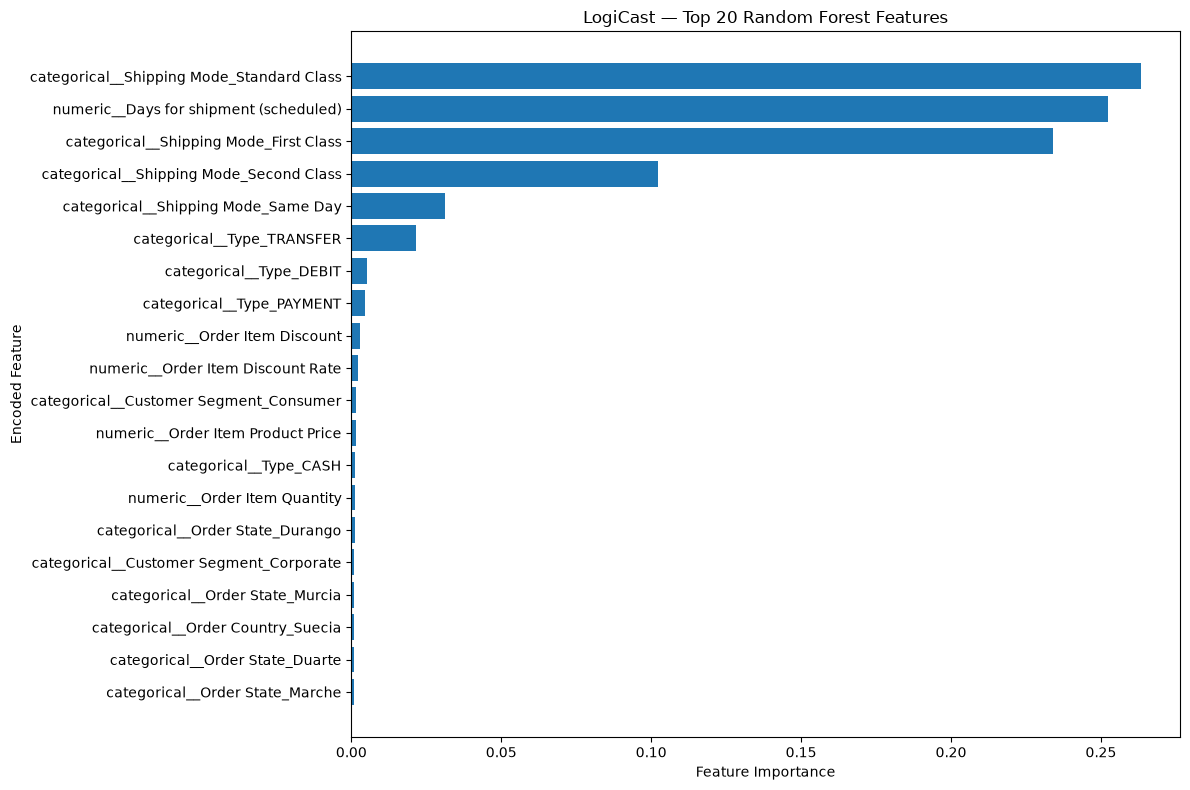

In [20]:
top_features = importance_df.head(20).sort_values(
    "Importance",
    ascending=True
)

plt.figure(figsize=(12, 8))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Encoded Feature")
plt.title("LogiCast — Top 20 Random Forest Features")
plt.tight_layout()
plt.show()

In [21]:
REPORT_DIR = PROJECT_ROOT / "reports"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

IMPORTANCE_PATH = (
    REPORT_DIR / "feature_importance.csv"
)

importance_df.to_csv(
    IMPORTANCE_PATH,
    index=False
)

print("Feature importance saved to:", IMPORTANCE_PATH)

Feature importance saved to: /Users/Kushagra/Desktop/Code/LogiCast/reports/feature_importance.csv


In [22]:
INFERENCE_PATH = PROJECT_ROOT / "src" / "inference.py"

inference_code = '''
from pathlib import Path

import joblib
import pandas as pd


PROJECT_ROOT = Path(__file__).resolve().parents[1]
MODEL_DIR = PROJECT_ROOT / "src" / "models"

MODEL_PATH = MODEL_DIR / "best_baseline_model.joblib"
PREPROCESSOR_PATH = MODEL_DIR / "preprocessor.joblib"
FEATURES_PATH = (
    PROJECT_ROOT / "data" / "processed" / "feature_columns.txt"
)


def load_artifacts():
    """Load the trained model, preprocessor, and feature list."""
    model = joblib.load(MODEL_PATH)
    preprocessor = joblib.load(PREPROCESSOR_PATH)
    feature_cols = FEATURES_PATH.read_text().splitlines()

    return model, preprocessor, feature_cols


def predict_late_delivery(order: dict) -> dict:
    """
    Predict late-delivery risk for one order.

    The input must contain the original model features,
    including engineered order-date features.
    """
    model, preprocessor, feature_cols = load_artifacts()

    missing = [col for col in feature_cols if col not in order]
    if missing:
        raise ValueError(f"Missing required features: {missing}")

    order_df = pd.DataFrame(
        [{col: order[col] for col in feature_cols}],
        columns=feature_cols
    )

    transformed = preprocessor.transform(order_df)

    probability = float(
        model.predict_proba(transformed)[0][
            list(model.classes_).index(1)
        ]
    )

    prediction = int(model.predict(transformed)[0])

    return {
        "predicted_late_delivery_risk": prediction,
        "late_delivery_probability": round(probability, 4),
        "model": type(model).__name__,
    }
'''

INFERENCE_PATH.write_text(inference_code)

print("Inference module created:", INFERENCE_PATH)

Inference module created: /Users/Kushagra/Desktop/Code/LogiCast/src/inference.py


In [23]:
import json

# Create a sample order from the test dataset
sample_order = X_test.iloc[0].to_dict()

# Define output path
sample_path = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "sample_order.json"
)

sample_path.parent.mkdir(
    parents=True,
    exist_ok=True
)

# Save sample as JSON
with open(sample_path, "w") as f:
    json.dump(
        sample_order,
        f,
        indent=4,
        default=str
    )

print("Sample input saved to:", sample_path)
print("Number of input features:", len(sample_order))

Sample input saved to: /Users/Kushagra/Desktop/Code/LogiCast/data/processed/sample_order.json
Number of input features: 17


In [24]:
API_PATH = PROJECT_ROOT / "src" / "main.py"

api_code = '''
from typing import Any

from fastapi import FastAPI, HTTPException
from pydantic import BaseModel

from src.inference import predict_late_delivery

app = FastAPI(
    title="LogiCast API",
    description="Predict late-delivery risk for supply-chain orders.",
    version="1.0.0",
)


class PredictionRequest(BaseModel):
    order: dict[str, Any]


@app.get("/")
def root():
    return {
        "message": "Welcome to LogiCast API",
        "docs": "/docs",
        "health": "/health",
    }


@app.get("/health")
def health():
    return {"status": "healthy"}


@app.post("/predict")
def predict(request: PredictionRequest):
    try:
        result = predict_late_delivery(request.order)
        return result
    except ValueError as exc:
        raise HTTPException(
            status_code=400,
            detail=str(exc),
        ) from exc
    except Exception as exc:
        raise HTTPException(
            status_code=500,
            detail="Prediction failed. Check the server logs.",
        ) from exc
'''

API_PATH.write_text(api_code)

print("FastAPI application created:", API_PATH)

FastAPI application created: /Users/Kushagra/Desktop/Code/LogiCast/src/main.py


In [25]:
%pip install fastapi uvicorn


[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


SyntaxError: invalid syntax (1438267165.py, line 1)